# 02 — Predicting outage severity (Objective 1)

**Target:** peak % of customers out per (storm episode, county), as `log(1 + percent)` for regression and low (<1%) / medium (1–10%) / high (≥10%) for classification.
**Split:** train 2014–2019, validate 2020 (tuning / early stopping), test 2021–2022.
**Models:** storm-type baseline → linear / logistic → random forest → LightGBM. **SHAP** explains the LightGBM regressor.

In [1]:
# Works on Colab (Drive) or locally (repo checkout)
import os, sys, pathlib, warnings
warnings.filterwarnings("ignore")
try:
    if os.environ.get("LIGHTSOUT_PROJECT"):  # a repo checkout, e.g. run with nbconvert inside Colab
        raise ImportError
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT = pathlib.Path("/content/drive/MyDrive/LightsOut")
    ZIP = pathlib.Path("/content/drive/MyDrive/LightsOut_code.zip")
    if ZIP.exists():  # refresh code (src/, notebooks/) from the latest uploaded zip; data/ is untouched
        import zipfile; zipfile.ZipFile(ZIP).extractall(PROJECT)
    !pip -q install polars lifelines scikit-survival shap geopandas lightgbm
except ImportError:
    PROJECT = pathlib.Path(os.environ["LIGHTSOUT_PROJECT"]) if os.environ.get("LIGHTSOUT_PROJECT") else \
        pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(PROJECT / "src"))
os.chdir(PROJECT)

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from lightsout import config as C, viz
viz.setup()
df = pd.read_parquet(C.PROCESSED / "model_table.parquet")
print(f"{len(df):,} (storm episode, county) units, {df.fips.nunique():,} counties, years {df.year.min()}-{df.year.max()}")

226,389 (storm episode, county) units, 3,037 counties, years 2014-2022


In [2]:
from lightsout import models_severity as S
print(df.groupby("split")["severity"].value_counts(normalize=True).unstack().round(3))
fit = S.fit_all(df)

severity    low  medium   high
split                         
test      0.719   0.205  0.076
train     0.761   0.182  0.058
val       0.700   0.214  0.086


In [3]:
res_val, res_test = S.results_table(fit, "val"), S.results_table(fit, "test")
res_test.to_csv(C.REPORTS / "severity_results_test.csv")
(C.REPORTS / "severity_results_test.md").write_text(res_test.to_markdown())
res_val.to_csv(C.REPORTS / "severity_results_val.csv")
print("LightGBM trees (stage 1 early-stopped / final refit):", fit["n_iter"])
print("Decision weights for F1-tuned cutoffs (fit on 2020):", fit["decision_weights"])
print("Validation (2020, models trained 2014-2019)"); display(res_val)
print("Test (2021-2022, models refit on 2014-2020)"); display(res_test)

LightGBM trees (stage 1 early-stopped / final refit): {'stage1': {'reg': 1435, 'clf': 3330, 'cb_reg': 937, 'cb_clf': 521}, 'final': {'reg': 1736, 'clf': 4027, 'cb_reg': 1133, 'cb_clf': 630}}
Decision weights for F1-tuned cutoffs (fit on 2020): {'high': np.float64(1.0), 'low': np.float64(1.0), 'medium': np.float64(0.9)}
Validation (2020, models trained 2014-2019)


,RMSE (log),MAE (log),MAE (pct pts),macro F1,accuracy,recall low,recall medium,recall high
model,,,,,,,,
Baseline (storm type),0.950,0.682,3.284,0.345,0.706,0.993,0.000,0.130
Linear / logistic,0.859,0.600,3.106,0.522,0.621,0.655,0.505,0.631
Random forest,0.839,0.565,3.037,0.563,0.718,0.827,0.518,0.329
LightGBM,0.819,0.540,2.965,0.581,0.736,0.858,0.480,0.379
CatBoost,0.817,0.543,2.956,0.585,0.730,0.842,0.489,0.409
Ensemble (LightGBM + CatBoost),0.816,0.541,2.959,0.586,0.736,0.855,0.484,0.397
"Ensemble (LightGBM + CatBoost, F1-tuned cutoffs)",NaN,NaN,NaN,0.588,0.742,0.871,0.446,0.424
"Ensemble (LightGBM + CatBoost, high-recall cutoff)",NaN,NaN,NaN,0.584,0.728,0.844,0.437,0.500


Test (2021-2022, models refit on 2014-2020)


,RMSE (log),MAE (log),MAE (pct pts),macro F1,accuracy,recall low,recall medium,recall high
model,,,,,,,,
Baseline (storm type),0.941,0.667,2.948,0.296,0.719,0.997,0.000,0.028
Linear / logistic,0.848,0.587,2.784,0.519,0.643,0.696,0.481,0.580
Random forest,0.829,0.551,2.714,0.546,0.736,0.864,0.458,0.271
LightGBM,0.812,0.526,2.645,0.565,0.744,0.872,0.449,0.332
CatBoost,0.814,0.531,2.648,0.568,0.743,0.869,0.450,0.350
Ensemble (LightGBM + CatBoost),0.811,0.528,2.644,0.568,0.746,0.873,0.448,0.340
"Ensemble (LightGBM + CatBoost, F1-tuned cutoffs)",NaN,NaN,NaN,0.565,0.748,0.887,0.405,0.360
"Ensemble (LightGBM + CatBoost, high-recall cutoff)",NaN,NaN,NaN,0.571,0.739,0.865,0.409,0.443


In [4]:
# test predictions for notebook 04 (model error by SVI quartile), so it need not refit
pt = fit["pred"]["test"].copy()
pt["log_peak_pct"] = fit["truth"]["test"]["log_peak_pct"].to_numpy()
pt["svi_quartile"] = fit["truth"]["test"]["svi_quartile"].astype(str).to_numpy()
pt.astype({c: str for c in pt.columns if pt[c].dtype == object}).to_parquet(C.PROCESSED / "pred_severity_test.parquet", index=False)

### Uncertainty, per-class performance and hyperparameters
Cluster bootstrap over storm episodes (500 resamples) gives 95% intervals for the test metrics.

In [5]:
ci = S.bootstrap_ci(fit, "test", n_boot=500)
ci.to_csv(C.REPORTS / "severity_ci_test.csv"); (C.REPORTS / "severity_ci_test.md").write_text(ci.to_markdown())
ci

,RMSE (log) 95% CI,macro F1 95% CI,accuracy 95% CI
model,,,
Baseline (storm type),"[0.921, 0.957]","[0.289, 0.305]","[0.712, 0.726]"
Linear / logistic,"[0.832, 0.863]","[0.512, 0.525]","[0.636, 0.650]"
Random forest,"[0.812, 0.843]","[0.538, 0.555]","[0.730, 0.742]"
LightGBM,"[0.795, 0.826]","[0.556, 0.573]","[0.738, 0.750]"
CatBoost,"[0.797, 0.828]","[0.559, 0.576]","[0.737, 0.749]"
Ensemble (LightGBM + CatBoost),"[0.794, 0.825]","[0.559, 0.576]","[0.739, 0.751]"
"Ensemble (LightGBM + CatBoost, F1-tuned cutoffs)",NaN,"[0.556, 0.574]","[0.742, 0.754]"
"Ensemble (LightGBM + CatBoost, high-recall cutoff)",NaN,"[0.562, 0.578]","[0.734, 0.745]"


In [6]:
pc = pd.concat({"Ensemble (LightGBM + CatBoost)": S.per_class_table(fit, "Ensemble (LightGBM + CatBoost)|clf"),
                "Ensemble, F1-tuned cutoffs": S.per_class_table(fit, "Ensemble (LightGBM + CatBoost, F1-tuned cutoffs)|clf"),
                "Ensemble, high-recall cutoff": S.per_class_table(fit, "Ensemble (LightGBM + CatBoost, high-recall cutoff)|clf"),
                "Random forest": S.per_class_table(fit, "Random forest|clf")})
pc.to_csv(C.REPORTS / "severity_per_class_test.csv"); (C.REPORTS / "severity_per_class_test.md").write_text(pc.to_markdown())
pc

precision  recall     F1      n
Ensemble (LightGBM + CatBoost) low         0.834   0.873  0.853  45435
                               medium      0.488   0.448  0.467  12958
                               high        0.438   0.340  0.383   4803
Ensemble, F1-tuned cutoffs     low         0.828   0.887  0.856  45435
                               medium      0.502   0.405  0.448  12958
                               high        0.429   0.360  0.392   4803
Ensemble, high-recall cutoff   low         0.837   0.865  0.851  45435
                               medium      0.490   0.409  0.446  12958
                               high        0.393   0.443  0.416   4803
Random forest                  low         0.828   0.864  0.846  45435
                               medium      0.467   0.458  0.463  12958
                               high        0.422   0.271  0.330   4803

### Operating point for high-severity outages
Accuracy alone rewards predicting "low" (72% of test rows). We report how well the model ranks high-severity outages (AUC, average precision) and choose the cutoff on purpose: the smallest P(high) that catches 50% of 2020's high-severity outages, then apply it unchanged to 2021-22.

In [7]:
op = S.operating_table(fit)
op.to_csv(C.REPORTS / "severity_operating_point.csv"); (C.REPORTS / "severity_operating_point.md").write_text(op.to_markdown())
print("P(high) cutoff fit on 2020:", fit["high_cutoff"]); op

P(high) cutoff fit on 2020: 0.3337


split,val,test
high share,0.086,0.076
AUC (high vs rest),0.872,0.852
average precision (high),0.433,0.385
LightGBM: recall high,0.379,0.332
LightGBM: precision high,0.458,0.434
CatBoost: recall high,0.409,0.350
CatBoost: precision high,0.459,0.426
Ensemble (LightGBM + CatBoost): recall high,0.397,0.340
Ensemble (LightGBM + CatBoost): precision high,0.468,0.438
"Ensemble (LightGBM + CatBoost, F1-tuned cutoffs): recall high",0.424,0.360


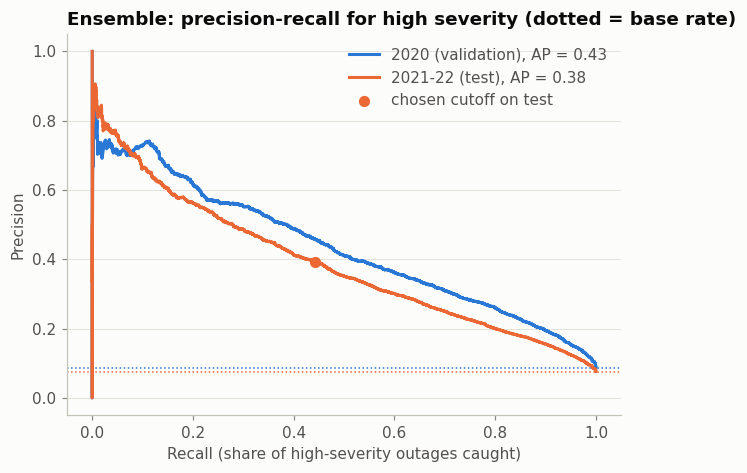

In [8]:
from sklearn.metrics import precision_recall_curve, average_precision_score
j = list(fit["classes"]).index("high")
fig, ax = plt.subplots(figsize=(6.5, 4.5))
for (split, label), col in zip([("val", "2020 (validation)"), ("test", "2021-22 (test)")], viz.CATEGORICAL):
    y = fit["truth"][split].severity.astype(str).to_numpy() == "high"
    prec, rec, _ = precision_recall_curve(y, fit["proba"][split][:, j])
    ax.plot(rec, prec, color=col, label=f"{label}, AP = {average_precision_score(y, fit['proba'][split][:, j]):.2f}")
    ax.axhline(y.mean(), color=col, linestyle=":", linewidth=1)
yt = fit["truth"]["test"].severity.astype(str).to_numpy() == "high"
pt = fit["pred"]["test"]["Ensemble (LightGBM + CatBoost, high-recall cutoff)|clf"].astype(str).to_numpy() == "high"
ax.scatter([(pt & yt).sum() / yt.sum()], [(pt & yt).sum() / pt.sum()], color=viz.CATEGORICAL[1], zorder=3, s=40,
           label="chosen cutoff on test")
ax.set_xlabel("Recall (share of high-severity outages caught)"); ax.set_ylabel("Precision")
ax.set_title("Ensemble: precision-recall for high severity (dotted = base rate)"); ax.legend()
viz.save(fig, "06b_high_severity_pr_curve"); fig

In [9]:
hp = S.hyperparameter_table()
hp.to_csv(C.REPORTS / "hyperparameters_severity.csv", index=False)
(C.REPORTS / "hyperparameters_severity.md").write_text(hp.to_markdown(index=False))
hp

,model,hyperparameter,value
0,Baseline (storm type),rule,mean (regression) / most common class per stor...
1,Ridge,alpha,1000.0
2,Logistic,C,10.0
3,Logistic,class_weight,balanced
4,Logistic,max_iter,3000
5,Random forest (both),n_estimators,300
6,Random forest regressor,max_features,0.5
7,Random forest regressor,min_samples_leaf,6
8,Random forest regressor,max_depth,20
9,Random forest regressor,max_samples,0.35


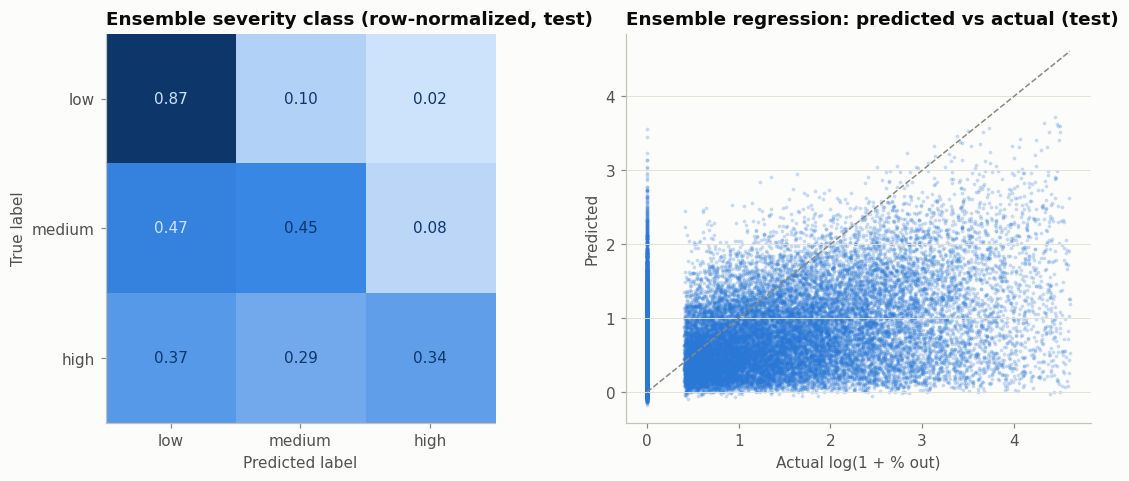

In [10]:
from sklearn.metrics import ConfusionMatrixDisplay
te = fit["truth"]["test"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
ConfusionMatrixDisplay.from_predictions(te.severity.astype(str), fit["pred"]["test"]["Ensemble (LightGBM + CatBoost)|clf"],
    labels=["low", "medium", "high"], normalize="true", cmap=viz.SEQUENTIAL_CMAP, ax=axes[0],
    values_format=".2f", colorbar=False)
axes[0].set_title("Ensemble severity class (row-normalized, test)"); axes[0].grid(False)
p = fit["pred"]["test"]["Ensemble (LightGBM + CatBoost)|reg"]
axes[1].scatter(te.log_peak_pct, p, s=6, alpha=0.25, color=viz.CATEGORICAL[0], linewidths=0)
lim = [0, max(te.log_peak_pct.max(), p.max())]
axes[1].plot(lim, lim, color=viz.MUTED, linewidth=1, linestyle="--")
axes[1].set_xlabel("Actual log(1 + % out)"); axes[1].set_ylabel("Predicted")
axes[1].set_title("Ensemble regression: predicted vs actual (test)")
viz.save(fig, "06_severity_test_diagnostics"); fig

In [11]:
# per storm type: does the best model beat the baseline everywhere?
pt = fit["pred"]["test"]
by_type = pd.DataFrame({
    "n": te.groupby("storm_type").size(),
    "baseline MAE": (te.log_peak_pct - pt["Baseline (storm type)|reg"]).abs().groupby(te.storm_type).mean(),
    "Ensemble MAE": (te.log_peak_pct - pt["Ensemble (LightGBM + CatBoost)|reg"]).abs().groupby(te.storm_type).mean(),
}).round(3).sort_values("n", ascending=False)
by_type

,n,baseline MAE,Ensemble MAE
storm_type,,,
wind,23295,0.870,0.626
winter,22666,0.514,0.445
flood,5416,0.531,0.470
hail,4280,0.429,0.380
heat,3865,0.472,0.435
tornado,1948,1.054,0.759
ice,546,1.339,1.156
wildfire,528,0.455,0.450
tropical,434,1.229,0.881


## SHAP: what drives predicted severity?

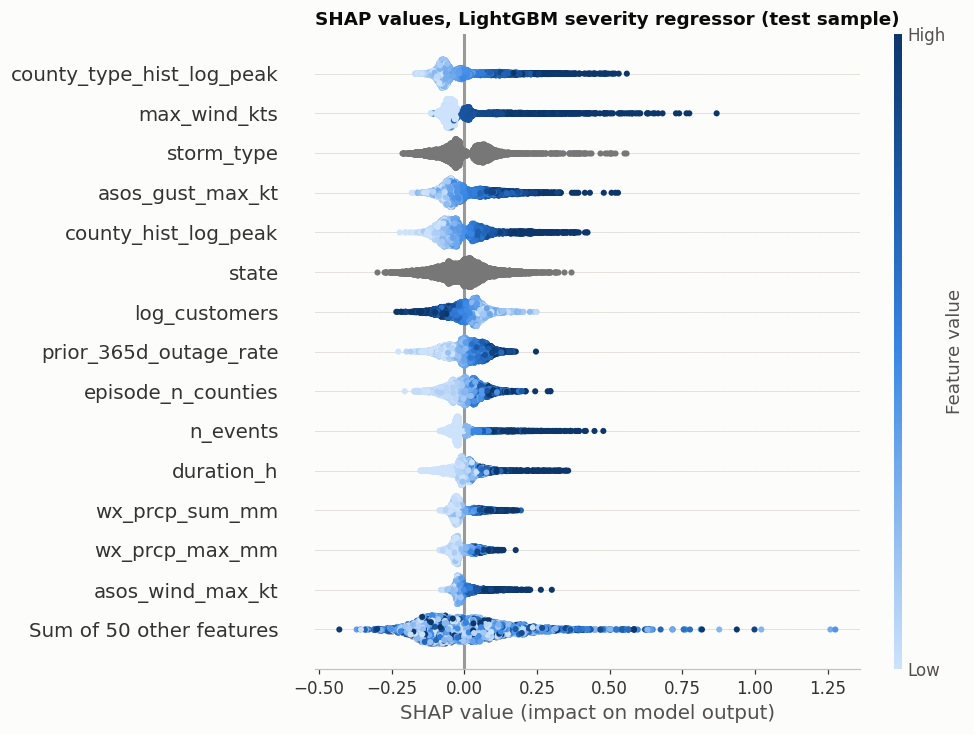

In [12]:
import shap
sv, X = S.shap_values(fit, n=5000)
plt.figure()
shap.plots.beeswarm(sv, max_display=15, show=False, color=viz.SEQUENTIAL_CMAP)
plt.title("SHAP values, LightGBM severity regressor (test sample)")
fig = plt.gcf(); viz.save(fig, "07_shap_summary"); fig

In [13]:
imp = pd.Series(np.abs(sv.values).mean(0), index=X.columns).sort_values(ascending=False)
imp.head(15).round(4).to_frame("mean |SHAP|")

,mean |SHAP|
county_type_hist_log_peak,0.0827
max_wind_kts,0.0702
storm_type,0.0694
asos_gust_max_kt,0.0685
county_hist_log_peak,0.0685
state,0.0667
log_customers,0.0491
prior_365d_outage_rate,0.0486
episode_n_counties,0.0458
n_events,0.0423


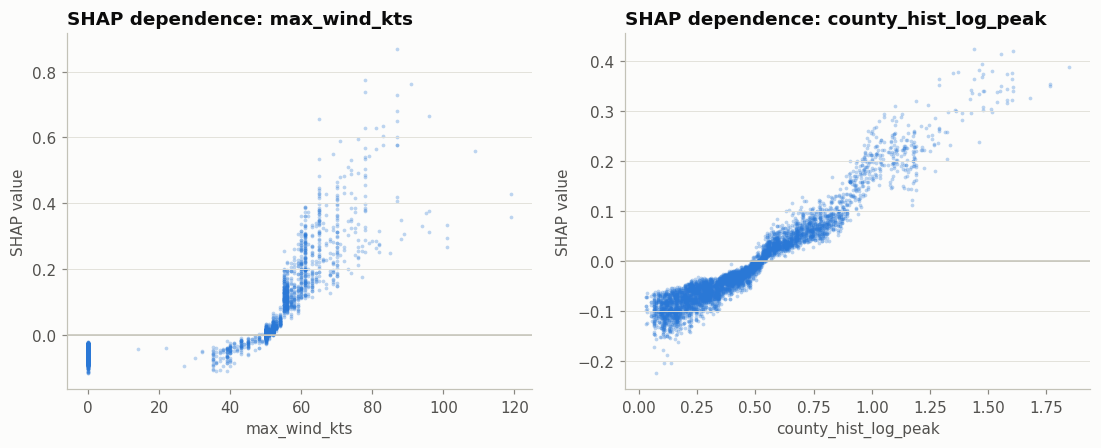

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, feat in zip(axes, ["max_wind_kts", "county_hist_log_peak"]):
    j = list(X.columns).index(feat)
    ax.scatter(X[feat], sv.values[:, j], s=6, alpha=0.3, color=viz.CATEGORICAL[0], linewidths=0)
    ax.axhline(0, color=viz.AXIS, linewidth=1)
    ax.set_xlabel(feat); ax.set_ylabel("SHAP value"); ax.set_title(f"SHAP dependence: {feat}")
viz.save(fig, "08_shap_dependence"); fig